In [2]:
# 이 셀은 타이타닉 데이터의 빈칸 처리와 범주형 문자 변환을 위한 함수들을 정의합니다.
# 함수만 정의하므로, 호출 전까지 데이터프레임은 아직 바뀌지 않습니다.




#   컴퓨터 모델은 보통 글자 범주를 그대로 계산할 수 없어 LabelEncoder를 사용합니다.

# 함수 정의는 레시피를 만드는 단계입니다. 실제 실행은 아래 셀에서 transform_features(X_df)로 요청합니다.
from sklearn.preprocessing import LabelEncoder

def fillna(df): # `fillna(df)`: 데이터 표 df를 받아 비어 있는 Age, Cabin, Embarked 값을 채웁니다.
    df["Age"] = df["Age"].fillna(df["Age"].mean())
    df["Cabin"] = df["Cabin"].fillna("N")
    df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
    #Age는 나이 평균, Cabin은 N(정보 없음 표시), Embarked는 가장 자주 나온 값으로 채웁니다.
    return df

def drop_features(df): # `drop_features(df)`: 예측에 사용하지 않을 PassengerId, Name, Ticket 열을 표에서 제거합니다.
    df.drop(["PassengerId", "Name", "Ticket"], axis=1, inplace=True)
    return df

def format_features(df): # `format_features(df)`: Cabin의 첫 글자만 남기고, 글자로 된 Cabin/Sex/Embarked를 숫자 코드로 바꿉니다.
    df["Cabin"] = df["Cabin"].str[0]
    features = ["Cabin", "Sex", "Embarked"]
    for feature in features:
        encoder = LabelEncoder()
        df[feature] = encoder.fit_transform(df[feature])
    return df

def transform_features(df): # `transform_features(df)`: 위 세 단계를 차례로 실행해 모델에 넣기 좋은 형태의 표를 돌려줍니다.
    df = fillna(df)
    df = drop_features(df)
    df = format_features(df)
    return df

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split


df = pd.read_csv("./train.csv")
# `Survived`는 맞혀야 할 정답(y), 나머지 열은 예측에 쓰는 입력(X)입니다.
y_df = df["Survived"] 
# `drop`은 지정한 열을 제외한 새 표를 만들며, `transform_features`가 빈칸과 글자값을 처리합니다.
X_df = df.drop("Survived",axis =1)
X_df = transform_features(X_df)

X_train,X_test,y_train, y_test = train_test_split( X_df,y_df,test_size = 0.2 ,  random_state=42) # 학습용과 평가용 데이터를 8:2로 나눕니다.
# `test_size=0.2`는 전체의 20%를 평가용으로 떼어 둔다는 뜻입니다.
# `train_test_split`은 데이터를 나눕니다. X_train/y_train으로 학습하고 X_test/y_test로 성능을 확인합니다.

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression

# 로지스틱 회귀 모델을 만들고 학습 데이터의 패턴을 학습시킨 뒤, 테스트 데이터의 생존 여부를 예측합니다.
lr_slf = LogisticRegression(solver = "liblinear") 
# `LogisticRegression`은 입력 특성을 바탕으로 두 범주(여기서는 생존/사망)를 분류하는 모델입니다.
# `solver`는 모델이 학습할 때 사용할 계산 방법을 지정합니다.

lr_slf.fit(X_train,y_train)
# `fit(X_train, y_train)`은 입력과 정답을 보고 모델의 기준을 학습합니다.
pred = lr_slf.predict(X_test)
# `predict(X_test)`는 학습이 끝난 모델로 테스트 데이터의 정답을 예측합니다.

In [ ]:

# 아래 지표 함수들은 예측(pred)과 실제 정답(y_test)을 비교해 성능을 숫자로 요약합니다.

from sklearn.metrics import accuracy_score,precision_score,recall_score
from sklearn.metrics import confusion_matrix

# 예측 결과를 혼동 행렬, 정확도, 정밀도, 재현율로 평가합니다.
confusion = confusion_matrix(y_test, pred) # 혼동행렬
accuracy = accuracy_score(y_test,pred) # 정확도
precision = precision_score(y_test, pred) # 정밀도
recall = recall_score(y_test,pred) # 재현율


print(confusion,accuracy,precision,recall)



[[89 16]
 [22 52]] 0.7877094972067039 0.7647058823529411 0.7027027027027027


In [ ]:
# predict_proba는 각 클래스일 확률을 반환합니다. 마지막 열에 실제 예측 라벨도 붙여 몇 개를 확인합니다.
# `predict_proba`는 각 행이 각 클래스일 확률을 반환합니다. 두 열은 보통 사망(0), 생존(1) 확률입니다.
pred_proba = lr_slf.predict_proba(X_test)

# `shape`는 배열의 (행 수, 열 수), `[:3]`은 앞의 세 행을 뜻합니다.
print("pred_proba() 결과 shape : ", pred_proba.shape)
print("pred_proba array 앞 3개의 샘플", pred_proba[:3])

# `concatenate(..., axis=1)`은 배열을 열 방향으로 이어 붙입니다.
# `reshape(-1, 1)`은 1차원 예측 결과를 세로 한 열짜리 배열로 바꿉니다.
pred_proba_result = np.concatenate([pred_proba, pred.reshape(-1,1)],axis =1)

print("두개의 클래스 중에서 더 큰 확률을 클래스의 값으로 예측",pred_proba_result[:3])

pred_proba() 결과 shape :  (179, 2)
pred_proba array 앞 3개의 샘플 [[0.88465353 0.11534647]
 [0.79433559 0.20566441]
 [0.85248383 0.14751617]]
두개의 클래스 중에서 더 큰 확률을 클래스의 값으로 예측 [[0.88465353 0.11534647 0.        ]
 [0.79433559 0.20566441 0.        ]
 [0.85248383 0.14751617 0.        ]]


In [ ]:
# 아래 예시는 작은 배열에서 이 변환이 어떻게 되는지 보여줍니다.
# `Binarizer`는 숫자를 0 또는 1로 바꾸는 도구입니다.
from sklearn.preprocessing import Binarizer

X =[ [1,-1,2],
    [2,0,0,],
    [0,1.1,1.2]]


# Binarizer는 기준값(threshold)보다 큰 값을 1, 나머지를 0으로 바꿉니다.
# `threshold=1.1`이면 1.1보다 큰 값은 1, 그 이하 값은 0이 됩니다.
binarizer = Binarizer(threshold= 1.1)


# `fit_transform`은 기준에 맞춰 변환을 적용합니다. 이 도구는 여기서 학습할 데이터가 따로 필요하지 않습니다.
print(binarizer.fit_transform(X))

[[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]]


In [ ]:

# 클래스 1일 확률에 새 기준값 0.6을 적용해 라벨을 다시 정하고, 그 결과의 분류 지표를 계산합니다.
# 확률이 0.5보다 커야 생존으로 보는 기본 기준 대신 0.6을 사용해 봅니다.
# 기준을 높이면 생존 판정이 더 까다로워져 정밀도와 재현율이 달라질 수 있습니다.
custom_threshold = 0.6

# `Binarizer`로 확률을 0/1 라벨로 바꾸고, 실제 정답과 비교해 분류 지표를 다시 계산합니다.
# `pred_proba[:, 1]`은 각 사람의 생존(클래스 1) 확률만 선택합니다.
pred_proba_1 = pred_proba[:, 1].reshape(-1,1)
binarizer = Binarizer(threshold= custom_threshold).fit(pred_proba_1)
custom_pred = binarizer.transform(pred_proba_1)


confusion = confusion_matrix(y_test, custom_pred) # 예측
accuracy = accuracy_score(y_test,custom_pred) # 예측 정확도
precision = precision_score(y_test, custom_pred) # 예측 정확도 퍼센트
recall = recall_score(y_test,custom_pred) # 실제 생존 비율


print(confusion,accuracy,precision,recall)


[[94 11]
 [23 51]] 0.8100558659217877 0.8225806451612904 0.6891891891891891


In [ ]:
# 여러 임계값에서 정밀도와 재현율이 어떻게 바뀌는지 계산하고, 일부 값만 골라 출력합니다.
# 임계값 배열은 정밀도/재현율 배열보다 원소가 하나 적을 수 있습니다.

from sklearn.metrics import precision_recall_curve as sklearn_precision_recall_curve
import numpy as np

pred_proba_class1 = lr_slf.predict_proba(X_test)[:, 1] # `pred_proba_class1`은 각 표본이 클래스 1일 확률이고, 실제 정답과 함께 함수에 전달합니다.
precisions, recalls, thresholds = sklearn_precision_recall_curve(
    y_test, pred_proba_class1
)

print("임계값 배열의 모양:", thresholds.shape)
print("정밀도 배열의 모양:", precisions.shape)
print("재현율 배열의 모양:", recalls.shape)
print("first 5 thresholds:", thresholds[:5])
print("first 5 precisions:", precisions[:5])
print("first 5 recalls:", recalls[:5])

thr_index = np.arange(0, len(thresholds), 15) # `np.arange(0, 길이, 15)`는 15칸 간격으로 확인할 위치를 만듭니다.
print("샘플 인덱스:", thr_index)
print("샘플 임계값:", np.round(thresholds[thr_index], 2))
print("샘플 임계값별 정밀도:",
      np.round(precisions[thr_index], 3)) # `np.round`는 출력 숫자를 보기 쉽게 반올림합니다.
print("샘플 임계값별 재현율:",
      np.round(recalls[thr_index], 3))


임계값 배열의 모양: (168,)
정밀도 배열의 모양: (169,)
재현율 배열의 모양: (169,)
first 5 thresholds: [0.0932581  0.09503487 0.09684188 0.09779005 0.09846972]
first 5 precisions: [0.42774566 0.4244186  0.42690058 0.42941176 0.43195266]
first 5 recalls: [1.         0.98648649 0.98648649 0.98648649 0.98648649]
샘플 인덱스: [  0  15  30  45  60  75  90 105 120 135 150 165]
샘플 임계값: [0.09 0.12 0.14 0.15 0.2  0.3  0.36 0.56 0.66 0.73 0.87 0.93]
샘플 임계값별 정밀도: [0.428 0.452 0.5   0.565 0.615 0.691 0.734 0.797 0.917 1.    1.    1.   ]
샘플 임계값별 재현율: [1.    0.959 0.946 0.946 0.905 0.878 0.784 0.689 0.595 0.446 0.243 0.041]


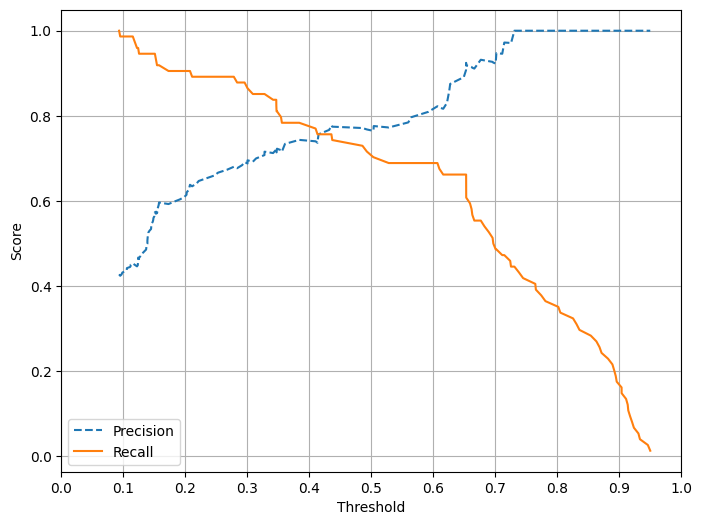

In [ ]:
# 임계값에 따른 정밀도와 재현율을 선 그래프로 그리는 함수를 정의하고 실행합니다.
# 함수 안에서 임계값별 정밀도/재현율을 구한 뒤, `plt.plot`으로 선을 그립니다.
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve as sklearn_precision_recall_curve


# `plot_precision_recall_curve`는 실제 정답과 클래스 1 확률을 받아 그래프를 그리는 사용자 정의 함수입니다.
def plot_precision_recall_curve(y_true, pred_proba_class1):
    precisions, recalls, thresholds = sklearn_precision_recall_curve(
        y_true, pred_proba_class1
    )
    threshold_count = len(thresholds) # `threshold_count`에 맞춰 점수 배열을 자르는 이유는 임계값보다 정밀도/재현율 원소가 하나 더 많을 수 있기 때문입니다.

    plt.figure(figsize=(8, 6))
    plt.plot(thresholds, precisions[:threshold_count], "--", label="Precision")
    plt.plot(thresholds, recalls[:threshold_count], label="Recall")
    plt.xticks(np.round(np.arange(0, 1.01, 0.1), 2))
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.legend()
    plt.grid(True)
    plt.show()


# 마지막 호출은 이 함수를 테스트 정답과 모델의 생존 확률로 실행합니다.
plot_precision_recall_curve(y_test, lr_slf.predict_proba(X_test)[:, 1])

## 이 그래프느 ROC아님!


In [ ]:
# F1 점수는 정밀도와 재현율을 함께 고려한 조화평균입니다.
from sklearn.metrics import f1_score

# `f1_score`는 정밀도와 재현율을 함께 고려하는 점수입니다. 두 값이 모두 높을 때 F1도 높습니다.
# 여기서는 기본 임계값으로 만든 `pred`와 실제 정답 `y_test`를 비교합니다.
f1 = f1_score(y_test, pred)
print(f1) # 비교 결과를 바탕으로 출력한 F1숫자

0.7323943661971832


In [ ]:
# ROC 곡선의 점들을 만들기 위해 임계값별 거짓 양성률(FPR)과 참 양성률(TPR = 재현율)을 계산합니다.
# ROC 곡선은 분류 기준을 바꿀 때 거짓 양성률(FPR)과 참 양성률(TPR)이 어떻게 달라지는지 보여줍니다.

from sklearn.metrics import roc_curve

pred_proba_class1 = lr_slf.predict_proba(X_test)[:,1]

fprs , tprs, thresholds = roc_curve ( y_test, pred_proba_class1) # `roc_curve`에는 실제 정답과 생존 확률을 넣습니다.
# `thr_index`는 모든 결과 중 일부 위치만 골라 출력하기 위한 인덱스입니다.
thr_index = np.arange(1, thresholds.shape[0], 5)
print(np.round(fprs[thr_index],3))
print(np.round(tprs[thr_index],3))

[0.    0.019 0.038 0.152 0.219 0.267 0.295 0.486 0.648 0.838]
[0.014 0.486 0.662 0.703 0.811 0.851 0.892 0.919 0.946 0.986]


In [ ]:
# ROC-AUC는 ROC 곡선 아래 면적으로, 확률 점수의 분류 능력을 요약합니다.
from sklearn.metrics import roc_auc_score

pred_proba_class1 = lr_slf.predict_proba(X_test)[:, 1]
# `roc_auc_score`는 실제 정답과 확률 점수로 ROC-AUC를 계산합니다.
roc_score = roc_auc_score(y_test, pred_proba_class1)

print(roc_score)

# 값이 1에 가까울수록 두 클래스를 잘 구분하고, 0.5 근처면 무작위 추측과 비슷합니다.

0.8787644787644788


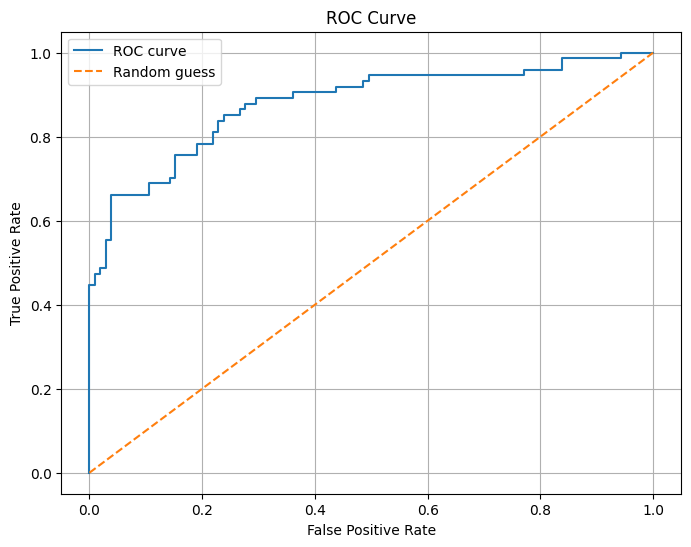

In [15]:
plt.figure(figsize=(8, 6))
plt.plot(fprs, tprs, label="ROC curve")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
# 바로 앞 셀과 같은 ROC-AUC 계산을 다시 수행합니다.
# 앞 셀과 동일하게 ROC-AUC를 다시 계산합니다. 같은 변수와 데이터를 사용하므로 결과도 같습니다.
from sklearn.metrics import roc_auc_score

pred_proba_class1 = lr_slf.predict_proba(X_test)[:, 1]
roc_score = roc_auc_score(y_test, pred_proba_class1)

print(roc_score)


0.8787644787644788
